# Video Signal Lab

An educational classification and leakage audit of Vedauv’s synthetic YouTube-style dataset. Establish which features exist before publication, calibrate predictions, compare a deliberately retrospective model, and inspect held-out decisions.

This notebook executes the source-locked pipeline and renders its measured results. Author: Fatgezim “Zim” Bela. Original analysis/application code: MIT. Source data retain the license and credit recorded in `source-lock.json`.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pipeline
from source import ROOT
plt.rcParams.update({'figure.figsize': (11,4), 'axes.spines.top':False, 'axes.spines.right':False, 'font.size':11})
print(json.dumps(json.loads((ROOT/'source-lock.json').read_text()), indent=2))

{
  "url": "https://www.kaggle.com/datasets/vedauv/what-makes-a-yt-video-go-viral-12000-vids",
  "download": "https://www.kaggle.com/api/v1/datasets/download/vedauv/what-makes-a-yt-video-go-viral-12000-vids?datasetVersionNumber=1",
  "version": 1,
  "sha256": "8f7c464ec382ab9d3ae50ede517548bd1940530dfe26f74ea64e2f2cbdf60b1d",
  "license": "CC0: Public Domain (Kaggle listing)",
  "classification": "Synthetic educational benchmark",
  "credit": "Vedauv Rajkumar Leelavathi / vedauv; dataset datasheet identifies generated observations."
}


## Execute the complete pipeline

The download is pinned by SHA-256. A mismatched archive stops the run. Model choices, seeds, parameters, preprocessing and artifact exports are implemented in `pipeline.py`.

In [2]:
report = pipeline.main()

{
  "quality": {
    "rows": 12000,
    "categories": 15,
    "missing_values": 0,
    "duplicates": 0,
    "viral_rate": 0.2,
    "views_cutoff": 734315.0
  },
  "winner": "Logistic regression",
  "metrics": [
    {
      "model": "Pre-upload metadata",
      "auc": 0.9064290364583334,
      "ap": 0.7271557193364806,
      "brier": 0.09392253083166442,
      "tn": 1806,
      "fp": 114,
      "fn": 218,
      "tp": 262
    },
    {
      "model": "Post-outcome engagement",
      "auc": 0.9873524305555555,
      "ap": 0.9576899923923887,
      "brier": 0.03521333171562028,
      "tn": 1882,
      "fp": 38,
      "fn": 90,
      "tp": 390
    },
    {
      "model": "Prevalence baseline",
      "auc": 0.5,
      "ap": 0.2,
      "brier": 0.16000000000000006,
      "tn": 1920,
      "fp": 0,
      "fn": 480,
      "tp": 0
    }
  ],
  "auc_ci95": [
    0.8923896382521088,
    0.9185901875189945
  ]
}


## Data contract and information timing

12,000 generated records, 15 categories, a 20% positive label defined from views. Likes/comments/shares are generated from views. Their availability after the outcome makes them inappropriate for pre-publication prediction. The comparison model deliberately includes them to make this failure mode measurable. Views and viral are excluded from both feature sets.

Use stratified 60/20/20 partitions with seeds 42/43. Candidate preprocessing and sigmoid calibration use three folds wholly inside the training split. Select the metadata model using validation average precision; retain the training-only fit and evaluate the test set with a fixed 0.50 threshold. Interactive threshold exploration is not a validated decision policy.

In [3]:
pd.DataFrame(report['candidates'])

,model,auc,ap,brier,tn,fp,fn,tp
0,Logistic regression,0.896531,0.704948,0.097322,1786,134,216,264
1,Gradient boosting,0.895567,0.698349,0.097654,1800,120,233,247


In [4]:
pd.DataFrame(report['metrics'])

,model,auc,ap,brier,tn,fp,fn,tp
0,Pre-upload metadata,0.906429,0.727156,0.093923,1806,114,218,262
1,Post-outcome engagement,0.987352,0.957690,0.035213,1882,38,90,390
2,Prevalence baseline,0.500000,0.200000,0.160000,1920,0,480,0


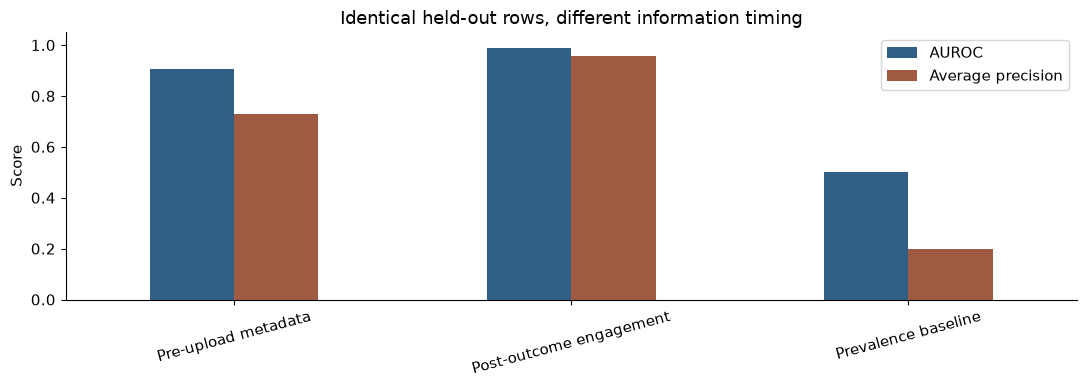

In [5]:
m=pd.DataFrame(report['metrics']).set_index('model')
ax=m[['auc','ap']].plot.bar(color=['#305e87','#a15a42'],rot=15)
ax.set(ylim=(0,1.05),ylabel='Score',xlabel='',title='Identical held-out rows, different information timing')
ax.legend(['AUROC','Average precision']);plt.tight_layout();plt.show()

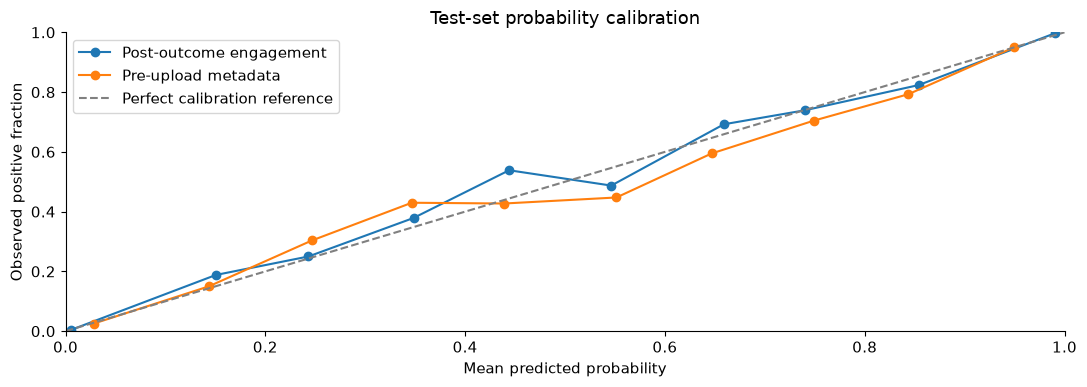

In [6]:
cal=pd.DataFrame(report['calibration'])
fig,ax=plt.subplots()
for label,group in cal.groupby('model'):
 ax.plot(group.predicted,group.observed,marker='o',label=label)
ax.plot([0,1],[0,1],color='grey',linestyle='--',label='Perfect calibration reference')
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted probability',ylabel='Observed positive fraction',title='Test-set probability calibration')
ax.legend();plt.tight_layout();plt.show()

In [7]:
pd.DataFrame(report['importance']).sort_values('ap_decrease',ascending=False)

,feature,ap_decrease,std
6,log_subscribers,0.497182,0.004775
2,thumbnail_face,0.009831,0.002475
4,tags_count,0.000633,0.001385
5,description_length,0.000590,0.000276
3,upload_hour,0.000113,0.000979
1,title_length,0.000062,0.000254
7,category,-0.000057,0.000688
8,upload_day,-0.000458,0.000626
0,duration_sec,-0.000503,0.000299


## Limits and next study

These scores measure a synthetic generator, not YouTube success. No channel IDs or real dated observations are provided, so future-period and channel-held-out evaluation are impossible with this source. Subscriber count can dominate generated outcomes; permutation importance is a model-reliance measurement, not a causal finding. The bootstrap AUROC interval resamples synthetic test records. Small category slices have higher uncertainty; their rates must retain denominators.

A real follow-up would require licensed timestamped observations, a fixed prediction horizon and exposure-adjusted target, channel/time separation, and deployment calibration. [Source dataset and author](https://www.kaggle.com/datasets/vedauv/what-makes-a-yt-video-go-viral-12000-vids). The source datasheet is included verbatim in `artifacts/datasheet.md`.

## Verify invariants

Tests check source/partition reconciliation and the properties that prevent misleading results.

In [8]:
import subprocess,sys
result=subprocess.run([sys.executable,'-m','pytest','tests','-q'],cwd=ROOT,capture_output=True,text=True)
print(result.stdout)
assert result.returncode==0, result.stderr

.....                                                                    [100%]
5 passed in 0.87s



## Reproduce and inspect

The README lists environment setup, app build and preview commands. `artifacts/test-predictions.csv` contains the held-out predictions; `artifacts/analysis.json` contains all application evidence. The app renders fixed, reproducible results and offers source inspection. Raw source archives and locally fitted models remain outside the public bundle; the locked downloader recreates them.